# **Fitur Unik 1: Penanganan Ketidakseimbangan Kelas (Focal Loss dan Threshold Optimal)**

Notebook 04 menunjukkan bahwa model tanpa fitur unik cukup baik dalam mengurutkan risiko, tetapi dengan threshold bawaan 0,5 hanya sebagian kecil responden diabetes yang terdeteksi di data validation. Fitur unik pertama dirancang untuk mengatasi masalah ini lewat dua komponen:

1. **Komponen loss (saat training):** mengganti binary cross-entropy dengan **Focal Loss**, supaya model lebih fokus pada sampel yang sulit, yang kebanyakan adalah kasus diabetes.
2. **Komponen keputusan (setelah training):** mengganti threshold 0,5 dengan **threshold yang dipilih di data validation** berdasarkan kriteria yang sesuai untuk skrining.

Dampak tiap komponen diukur terpisah lewat desain **ablation 2 x 2** (loss BCE atau Focal, dikali threshold 0,5 atau threshold optimal). Dengan begitu bisa dilihat komponen mana yang benar-benar memberi perbaikan.

Arsitektur, learning rate, dan batch size diambil dari hasil akhir pencarian hyperparameter tanpa perubahan. Sumbernya ditentukan oleh keputusan uji konfirmasi di notebook 04b: `04b_konfigurasi_final.json` kalau konfigurasi diganti, atau `04_konfigurasi_final.json` kalau dipertahankan. Semua pemilihan dilakukan di data validation. **Data test tidak disentuh** sampai notebook 07.

**Penanggung jawab:** Johannes Hartanto (231110730)

## **1. Import Library dan Konfigurasi**

Eksperimen di notebook ini melatih 16 model (5 variasi loss x 3 seed, ditambah 1 model final) dan butuh sekitar 20 sampai 30 menit di CPU. Hasil BCE dari notebook sebelumnya dipakai ulang. Saklar `RUN_EXPERIMENTS = False` memuat hasil yang tersimpan tanpa training ulang.

In [1]:
import sys
import json
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import StratifiedKFold

from src import config
from src import preprocessing as prep
from src import model as M
from src import evaluation as ev
from src import visualization as viz

RUN_EXPERIMENTS = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
viz.set_style()
WARNA_KELAS = {0: "#4C72B0", 1: "#DD8452"}
WARNA_METRIK = {"recall": "#2a78d6", "precision": "#eb6834", "f2": "#1baf7a"}

MODEL_FINAL_PATH = config.MODELS_DIR / "mlp_final.keras"
MODEL_CONFIG_PATH = config.MODELS_DIR / "model_config.json"
PROB_PATH = config.RESULTS_DIR / "05_prob_validation_seed42.npz"

print("TensorFlow :", tf.__version__)
print("RUN_EXPERIMENTS :", RUN_EXPERIMENTS)

TensorFlow : 2.21.0
RUN_EXPERIMENTS : False


## **2. Memuat Data, Konfigurasi, dan Model Tanpa Fitur Unik**

In [2]:
data = prep.prepare_datasets()
assert data["test_fingerprint"] == prep.load_preprocessing_config()["split"]["test_fingerprint"]
y_val = data["y_val"].astype(int)

keputusan_04b = M.load_json(config.RESULTS_DIR / "04b_keputusan.json")
SUMBER_KONFIG = "04b_konfigurasi_final.json" if keputusan_04b["ganti_konfigurasi"] else "04_konfigurasi_final.json"
konfig_dasar = M.load_json(config.RESULTS_DIR / SUMBER_KONFIG)
cfg_dasar = konfig_dasar["konfigurasi"]
MODEL_BCE_PATH = ROOT / konfig_dasar["model_path"]
model_bce = keras.models.load_model(MODEL_BCE_PATH)

n0, n1 = int((data["y_train"] == 0).sum()), int((data["y_train"] == 1).sum())
alpha_seimbang = round(n0 / (n0 + n1), 3)

print("Keputusan notebook 04b:", "konfigurasi diganti" if keputusan_04b["ganti_konfigurasi"] else "konfigurasi dipertahankan")
print("Sumber konfigurasi  :", SUMBER_KONFIG)
print("Konfigurasi dasar   :", M.config_label(cfg_dasar), "| lr", cfg_dasar["learning_rate"], "| batch", cfg_dasar["batch_size"])
print(f"Model tanpa fitur unik: {MODEL_BCE_PATH.relative_to(ROOT)} (val PR-AUC {konfig_dasar['model_final_val_pr_auc']:.4f})")
print(f"Train kelas 0 / 1   : {n0:,} / {n1:,}")
print(f"Alpha seimbang      : {alpha_seimbang} (proporsi kelas 0 di data train)")

Keputusan notebook 04b: konfigurasi diganti
Sumber konfigurasi  : 04b_konfigurasi_final.json
Konfigurasi dasar   : [128-64-32-16] do=0.0 l2=1e-06 BN lr=0.00439253 bs=256 | lr 0.0043925333029596605 | batch 256
Model tanpa fitur unik: models\mlp_tanpa_fitur_unik_rs.keras (val PR-AUC 0.4475)
Train kelas 0 / 1   : 135,700 / 24,511
Alpha seimbang      : 0.847 (proporsi kelas 0 di data train)


## **3. Cara Kerja Focal Loss dan Variasi yang Diuji**

Focal Loss diperkenalkan oleh Lin dkk. (2017) untuk deteksi objek, yang juga punya masalah kelas sangat tidak seimbang. Rumusnya:

$$FL(p_t) = -\alpha_t \, (1 - p_t)^{\gamma} \, \log(p_t)$$

dengan $p_t$ adalah probabilitas yang diberikan model untuk kelas yang benar.

- **Faktor $(1 - p_t)^{\gamma}$** mengecilkan loss untuk sampel yang sudah mudah ditebak dengan yakin. Pada data ini, sampel mudah kebanyakan adalah responden sehat dengan probabilitas diabetes mendekati 0. Akibatnya, porsi gradien lebih banyak berasal dari sampel yang sulit. Semakin besar $\gamma$, semakin kuat efeknya. Dengan $\gamma = 0$, Focal Loss sama dengan binary cross-entropy.
- **Faktor $\alpha_t$** memberi bobot per kelas. Kelas 1 diberi bobot $\alpha$ dan kelas 0 diberi bobot $1 - \alpha$.

Variasi yang diuji, semuanya dengan arsitektur dan hyperparameter yang sama:

| Kode | Loss | Alasan |
|---|---|---|
| `bce` | Binary cross-entropy | Pembanding (model tanpa fitur unik), hasil 3 seed-nya dipakai ulang dari notebook sebelumnya |
| `bce_berbobot` | Focal dengan $\gamma = 0$, $\alpha = 0{,}847$ | Setara dengan *class weight* seimbang. Pembanding untuk melihat apakah sekadar memberi bobot kelas sudah cukup |
| `focal_g1` | Focal $\gamma = 1$ | Efek focusing ringan |
| `focal_g2` | Focal $\gamma = 2$ | Nilai yang paling baik di paper aslinya |
| `focal_g3` | Focal $\gamma = 3$ | Efek focusing kuat |
| `focal_g2_a075` | Focal $\gamma = 2$, $\alpha = 0{,}75$ | Kombinasi focusing dan pembobotan kelas. Nilai 0,75 dipilih di tengah antara tanpa bobot (0,5) dan bobot seimbang (0,847) |

Model dipilih dengan aturan yang sama seperti notebook sebelumnya, berdasarkan PR-AUC validation. PR-AUC tidak bergantung pada threshold, jadi perbandingan ini murni mengukur kemampuan model mengurutkan risiko. Loss selain BCE dihitung sebagai komponen tambahan, sehingga Focal Loss hanya dipilih kalau hasilnya **lebih baik secara jelas** dibanding BCE.

In [3]:
loss_specs = {
    "bce": None,
    "bce_berbobot": {"type": "focal", "gamma": 0.0, "alpha": alpha_seimbang},
    "focal_g1": {"type": "focal", "gamma": 1.0, "alpha": None},
    "focal_g2": {"type": "focal", "gamma": 2.0, "alpha": None},
    "focal_g3": {"type": "focal", "gamma": 3.0, "alpha": None},
    "focal_g2_a075": {"type": "focal", "gamma": 2.0, "alpha": 0.75},
}
configs_e6 = {k: (dict(cfg_dasar) if spec is None else {**cfg_dasar, "loss_spec": spec})
              for k, spec in loss_specs.items()}
label_loss = {k: M.loss_label(spec) for k, spec in loss_specs.items()}
pd.DataFrame({"loss": label_loss, "komponen_tambahan": {k: M._extras(c) for k, c in configs_e6.items()}})

,loss,komponen_tambahan
bce,BCE,2
bce_berbobot,BCE berbobot (alpha=0.847),3
focal_g1,Focal (gamma=1),3
focal_g2,Focal (gamma=2),3
focal_g3,Focal (gamma=3),3
focal_g2_a075,"Focal (gamma=2, alpha=0.75)",4


## **4. Eksperimen E6: Perbandingan Fungsi Loss**

Kurva loss antar-variasi tidak bisa dibandingkan langsung karena skala tiap fungsi loss berbeda. Karena itu, EarlyStopping, ModelCheckpoint, dan pemilihan model tetap memakai PR-AUC validation, sama seperti notebook sebelumnya.

In [4]:
RUNS_PATH = config.RESULTS_DIR / "05_eksperimen_runs.csv"
HIST_PATH = config.RESULTS_DIR / "05_riwayat_training.json"

if RUN_EXPERIMENTS:
    # Hasil BCE 3 seed untuk konfigurasi dasar dicari di semua hasil eksperimen sebelumnya
    label_dasar = M.config_label(cfg_dasar)
    cache = {}
    sumber_runs = [("03_eksperimen_runs.csv", "03_riwayat_training.json"),
                   ("04_eksperimen_runs.csv", "04_riwayat_training.json"),
                   ("04b_konfirmasi_3seed.csv", "04b_riwayat_konfirmasi.json")]
    for f_runs, f_hist in sumber_runs:
        runs_lama, hist_lama = pd.read_csv(config.RESULTS_DIR / f_runs), M.load_json(config.RESULTS_DIR / f_hist)
        for _, r in runs_lama[runs_lama["config"] == label_dasar].drop_duplicates(["config", "seed"]).iterrows():
            if (label_dasar, int(r["seed"])) in cache:
                continue
            kunci = f"{r['tahap']}|{r['skenario']}|{int(r['seed'])}" if "tahap" in r else f"{r['skenario']}|{int(r['seed'])}"
            ringkasan = r.drop([c for c in ["tahap", "skenario", "cfg_json"] if c in r]).to_dict()
            ringkasan["seed"] = int(ringkasan["seed"])
            cache[(label_dasar, int(r["seed"]))] = (ringkasan, hist_lama[kunci])
    print(f"Dipakai ulang: {len(cache)} run BCE\n")

    t0 = time.time()
    runs_e6, hist_e6 = M.run_configs(configs_e6, data, prefix="E6", cache=cache)
    runs_e6.insert(0, "tahap", "E6")
    runs_e6.to_csv(RUNS_PATH, index=False)
    M.save_json(hist_e6, HIST_PATH)
    print(f"\nTotal waktu E6: {(time.time() - t0) / 60:.1f} menit")
else:
    runs_e6 = pd.read_csv(RUNS_PATH)
    hist_e6 = M.load_json(HIST_PATH)
    print(f"Memuat {len(runs_e6)} run dari {RUNS_PATH.relative_to(ROOT)}")

Memuat 18 run dari reports\results\05_eksperimen_runs.csv


,loss,parameter,val PR-AUC,std,val ROC-AUC,train PR-AUC,gap train-val,epoch terbaik,detik/run,setara terbaik,dipilih
skenario,,,,,,,,,,,
bce,BCE,14417,0.4479,0.0006,0.8188,0.4468,-0.0011,8.0,37.0,True,ya
bce_berbobot,BCE berbobot (alpha=0.847),14417,0.4470,0.0016,0.8186,0.4429,-0.0041,9.3,39.0,False,
focal_g1,Focal (gamma=1),14417,0.4474,0.0016,0.8186,0.4437,-0.0037,6.7,35.0,True,
focal_g2,Focal (gamma=2),14417,0.4477,0.0009,0.8187,0.4435,-0.0041,8.0,37.0,True,
focal_g3,Focal (gamma=3),14417,0.4466,0.0012,0.8187,0.4409,-0.0058,9.0,39.0,False,
focal_g2_a075,"Focal (gamma=2, alpha=0.75)",14417,0.4470,0.0011,0.8188,0.4409,-0.0061,10.7,43.0,False,


Loss terpilih untuk model final: bce -> BCE


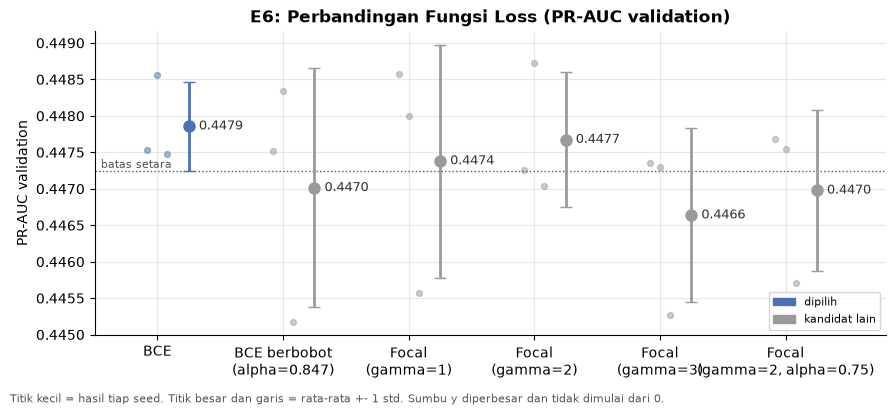

In [5]:
pilih_e6, ringkas_e6 = M.select_best(M.summarize(runs_e6))
cfg_final = configs_e6[pilih_e6]
tabel_e6 = viz.tabel_ringkas(ringkas_e6, pilih_e6)
tabel_e6.insert(0, "loss", [label_loss[k] for k in tabel_e6.index])
tabel_e6.to_csv(config.RESULTS_DIR / "05_ringkasan_skenario.csv")
display(tabel_e6.drop(columns=["konfigurasi"]))
print("Loss terpilih untuk model final:", pilih_e6, "->", label_loss[pilih_e6])

viz.plot_tahap(runs_e6, ringkas_e6, pilih_e6, "E6: Perbandingan Fungsi Loss (PR-AUC validation)",
               "fu1_01_e6_loss", label_x={k: label_loss[k].replace(" (", "\n(") for k in ringkas_e6.index})

**Interpretasi:** Hasil E6 menunjukkan bahwa **tidak ada variasi loss yang lebih baik dari BCE** dalam mengurutkan risiko. BCE justru mendapat rata-rata tertinggi (0,4479 +- 0,0006), dengan batas setara 0,4473.

- **Focal gamma 1** (0,4474) dan **Focal gamma 2** (0,4477) masih setara dengan BCE, tetapi tidak lebih baik.
- **BCE berbobot** (0,4470), **Focal gamma 3** (0,4466), dan **Focal gamma 2 dengan alpha 0,75** (0,4470) berada di bawah batas setara.
- PR-AUC train semua variasi Focal (0,4409 sampai 0,4437) lebih rendah dari BCE (0,4468). Menurunkan bobot sampel yang mudah membuat model sedikit kurang menyesuaikan diri dengan data, dan efeknya makin besar pada gamma yang lebih tinggi.

Kolom komponen tambahan pada tabel di atas bernilai 2 untuk BCE, karena konfigurasi dasarnya sudah memakai L2 dan BatchNorm. Loss selain BCE menambah satu komponen lagi. Sesuai aturan pemilihan, **BCE dipilih sebagai loss model final**. Kemampuan model mengurutkan risiko dibatasi oleh informasi di data, sehingga mengubah cara menghitung loss tidak membuat model lebih tajam.

## **5. Pengaruh Focal Loss pada Sebaran Probabilitas**

PR-AUC hanya melihat urutan risiko, sehingga perubahan bentuk probabilitas tidak terlihat di sana. Bagian ini membandingkan sebaran probabilitas model BCE (model tanpa fitur unik) dengan model Focal terbaik pada seed yang sama (42). Model Focal terbaik adalah variasi dengan $\gamma > 0$ yang rata-rata PR-AUC-nya paling tinggi. Model inilah yang dipakai di ablation 2 x 2.

Focal terbaik: focal_g2 -> Focal (gamma=2)
Proporsi diabetes sebenarnya di validation: 0.1530


,PR-AUC,ROC-AUC,rata-rata probabilitas,median prob. kelas diabetes,median prob. kelas tidak diabetes,"persen prob >= 0,5"
BCE,0.4475,0.8184,0.1397,0.2789,0.0661,0.0277
Focal (gamma=2),0.4473,0.8181,0.3018,0.4226,0.2813,0.0438


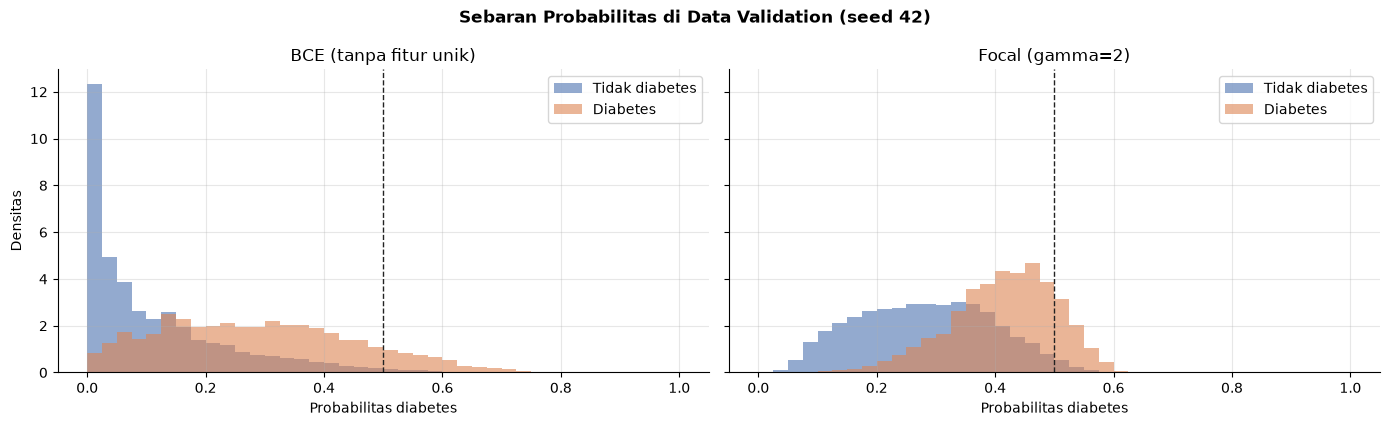

In [6]:
focal_keys = [k for k, s in loss_specs.items() if s is not None and s["gamma"] > 0]
focal_terbaik = ringkas_e6.loc[focal_keys, "val_pr_auc_mean"].idxmax()
print("Focal terbaik:", focal_terbaik, "->", label_loss[focal_terbaik])

if RUN_EXPERIMENTS:
    prob = {"bce": model_bce.predict(data["X_val"], batch_size=M.EVAL_BATCH, verbose=0).ravel()}
    m_focal = keras.models.load_model(M.CHECKPOINT_DIR / f"E6_{focal_terbaik}_seed42.keras")
    prob["focal"] = m_focal.predict(data["X_val"], batch_size=M.EVAL_BATCH, verbose=0).ravel()
else:
    tersimpan = np.load(PROB_PATH)
    prob = {"bce": tersimpan["bce"], "focal": tersimpan["focal"]}

ringkas_prob = pd.DataFrame({
    nama: {"PR-AUC": ev.ranking_metrics(y_val, p)["pr_auc"], "ROC-AUC": ev.ranking_metrics(y_val, p)["roc_auc"],
           "rata-rata probabilitas": p.mean(), "median prob. kelas diabetes": np.median(p[y_val == 1]),
           "median prob. kelas tidak diabetes": np.median(p[y_val == 0]), "persen prob >= 0,5": (p >= 0.5).mean()}
    for nama, p in [("BCE", prob["bce"]), (label_loss[focal_terbaik], prob["focal"])]
}).T
print(f"Proporsi diabetes sebenarnya di validation: {y_val.mean():.4f}")
display(ringkas_prob.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, (judul, p) in zip(axes, [("BCE (tanpa fitur unik)", prob["bce"]), (label_loss[focal_terbaik], prob["focal"])]):
    for k in [0, 1]:
        ax.hist(p[y_val == k], bins=bins, density=True, alpha=0.6, color=WARNA_KELAS[k], label=config.CLASS_LABELS[k])
    ax.axvline(0.5, color="#222222", ls="--", lw=1)
    ax.set_title(judul)
    ax.set_xlabel("Probabilitas diabetes")
    ax.legend()
axes[0].set_ylabel("Densitas")
fig.suptitle("Sebaran Probabilitas di Data Validation (seed 42)", fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "fu1_02_sebaran_probabilitas")
plt.show()

**Interpretasi:** Kedua model punya kemampuan mengurutkan risiko yang praktis sama (PR-AUC 0,4475 berbanding 0,4473, ROC-AUC 0,8184 berbanding 0,8181). Bedanya ada pada **bentuk probabilitas**:

- Pada model BCE, rata-rata probabilitasnya 0,1397, dekat dengan proporsi diabetes sebenarnya (0,1530). Probabilitas model BCE cukup masuk akal dibaca sebagai peluang.
- Pada model Focal gamma 2, rata-rata probabilitasnya 0,3018, sekitar dua kali proporsi sebenarnya. Histogram memperlihatkan probabilitasnya terkumpul di rentang sekitar 0,05 sampai 0,6 dan bergeser ke kanan. Median probabilitas responden tidak diabetes pun mencapai 0,2813.

Artinya, pada data ini Focal Loss terutama **menggeser dan memampatkan probabilitas**, bukan memperbaiki pemisahan antar-kelas. Untuk aplikasi, ini kerugian, karena angka probabilitas dari model Focal tidak lagi mencerminkan peluang yang sebenarnya.

## **6. Training Model Final**

Model final dilatih dengan loss terpilih dari E6, memakai seed 42 dan callback yang sama (EarlyStopping dan ModelCheckpoint pada PR-AUC validation). Model ini disimpan ke `models/mlp_final.keras` dan menjadi model yang dipakai di evaluasi akhir dan aplikasi.

Loss model final : BCE
Epoch dijalankan : 15 (terbaik di epoch 7)
PR-AUC validation: 0.4475 | ROC-AUC: 0.8184
File model       : models\mlp_final.keras (233.1 KB)


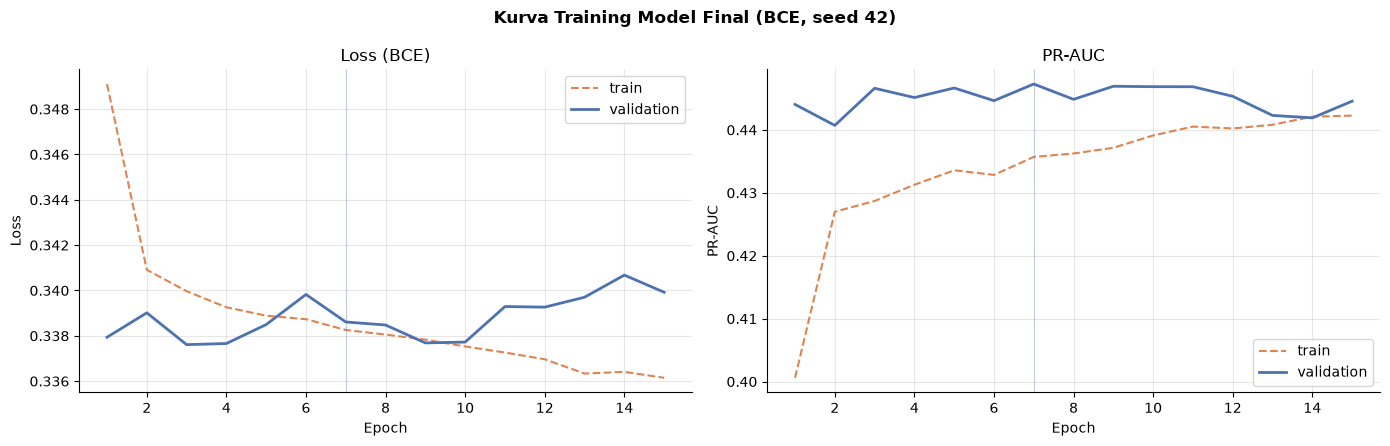

In [7]:
if RUN_EXPERIMENTS:
    model_final, ringkasan_final, hist_final = M.train_one(cfg_final, data, seed=42, run_name="final_fitur_unik1")
    model_final.save(MODEL_FINAL_PATH)
    M.save_json({"ringkasan": ringkasan_final, "history": hist_final}, config.RESULTS_DIR / "05_riwayat_model_final.json")
    prob["final"] = model_final.predict(data["X_val"], batch_size=M.EVAL_BATCH, verbose=0).ravel()
    np.savez_compressed(PROB_PATH, bce=prob["bce"], focal=prob["focal"], final=prob["final"])
else:
    model_final = keras.models.load_model(MODEL_FINAL_PATH)
    tersimpan_final = M.load_json(config.RESULTS_DIR / "05_riwayat_model_final.json")
    ringkasan_final, hist_final = tersimpan_final["ringkasan"], tersimpan_final["history"]
    prob["final"] = np.load(PROB_PATH)["final"]

print("Loss model final :", label_loss[pilih_e6])
print(f"Epoch dijalankan : {ringkasan_final['epochs_run']} (terbaik di epoch {ringkasan_final['best_epoch']})")
print(f"PR-AUC validation: {ringkasan_final['val_pr_auc']:.4f} | ROC-AUC: {ringkasan_final['val_roc_auc']:.4f}")
print(f"File model       : {MODEL_FINAL_PATH.relative_to(ROOT)} ({MODEL_FINAL_PATH.stat().st_size / 1024:.1f} KB)")

viz.plot_kurva({"seed 42": hist_final}, f"Kurva Training Model Final ({label_loss[pilih_e6]}, seed 42)",
               "fu1_03_kurva_model_final", loss_label=f"Loss ({label_loss[pilih_e6]})")

**Interpretasi:** Karena loss terpilih adalah BCE dengan konfigurasi dan seed yang sama, model final identik dengan model tanpa fitur unik dari notebook 04b. Keduanya berjalan 15 epoch dengan epoch terbaik di epoch 7, PR-AUC validation 0,4475, dan ROC-AUC 0,8184. Seperti dibahas di notebook 04b, kurva konfigurasi ini cukup naik-turun dan val loss mulai naik setelah sekitar epoch 10. EarlyStopping dan ModelCheckpoint menyimpan bobot sebelum hal itu terjadi.

Jadi di model final, fitur unik pertama bekerja di **tahap keputusan**, yaitu lewat threshold yang dipilih di bagian berikutnya, bukan di bobot model. File `mlp_final.keras` disimpan terpisah supaya aplikasi dan notebook evaluasi selalu merujuk ke satu nama file final yang jelas.

## **7. Memilih Threshold di Data Validation**

Threshold menentukan kapan probabilitas dianggap "berisiko diabetes". Empat kriteria dibandingkan pada probabilitas model final:

| Kriteria | Arti |
|---|---|
| F1 maksimum | Recall dan precision dianggap sama penting |
| **F2 maksimum** | Recall dianggap **dua kali lebih penting** daripada precision |
| Youden's J maksimum | Memaksimalkan recall + specificity - 1 |
| Recall minimal 80% | Precision tertinggi dengan syarat recall paling sedikit 80% |

**Kriteria yang dipakai adalah F2 maksimum**, dan ditetapkan sebelum melihat hasil. Alasannya, aplikasi ini berfungsi sebagai alat skrining awal. Melewatkan penderita diabetes (*false negative*) lebih merugikan, karena orang tersebut tidak terdorong memeriksakan diri. Sebaliknya, *false positive* paling jauh berujung pada anjuran cek gula darah, yang murah dan tidak berisiko. Sebagai pembanding, alat skrining mandiri dari American Diabetes Association dilaporkan bekerja pada sensitivitas 79% dan spesifisitas 67% (Bang dkk., 2009). Artinya alat skrining memang lazim menerima banyak *false positive* demi recall yang tinggi.

Ketiga kriteria lain tetap ditampilkan sebagai pembanding.

In [8]:
kurva_final = ev.threshold_curve(y_val, prob["final"])
kriteria = {"F1 maksimum": "f1", "F2 maksimum": "f2", "Youden's J maksimum": "youden_j", "Recall minimal 80%": "recall_min"}
tabel_kriteria = pd.DataFrame({nama: ev.metrics_at_threshold(y_val, prob["final"], ev.pick_threshold(kurva_final, k))
                               for nama, k in kriteria.items()}).T
tabel_kriteria.loc["Threshold bawaan 0,5"] = ev.metrics_at_threshold(y_val, prob["final"], 0.5)
kolom = ["threshold", "recall", "precision", "specificity", "f1", "f2", "accuracy", "persen_diprediksi_positif", "tp", "fp", "fn"]
display(tabel_kriteria[kolom].astype({"tp": int, "fp": int, "fn": int}).round(4))

THRESHOLD = ev.pick_threshold(kurva_final, "f2")
print(f"Threshold terpilih (F2 maksimum): {THRESHOLD}")

,threshold,recall,precision,specificity,f1,f2,accuracy,persen_diprediksi_positif,tp,fp,fn
F1 maksimum,0.220,0.6194,0.3925,0.8269,0.4805,0.5552,0.7951,0.2414,3253,5035,1999
F2 maksimum,0.130,0.8182,0.3065,0.6657,0.4460,0.6134,0.6890,0.4083,4297,9722,955
Youden's J maksimum,0.135,0.8054,0.3120,0.6792,0.4497,0.6119,0.6985,0.3949,4230,9329,1022
Recall minimal 80%,0.135,0.8054,0.3120,0.6792,0.4497,0.6119,0.6985,0.3949,4230,9329,1022
"Threshold bawaan 0,5",0.500,0.1156,0.6376,0.9881,0.1957,0.1382,0.8547,0.0277,607,345,4645


Threshold terpilih (F2 maksimum): 0.13


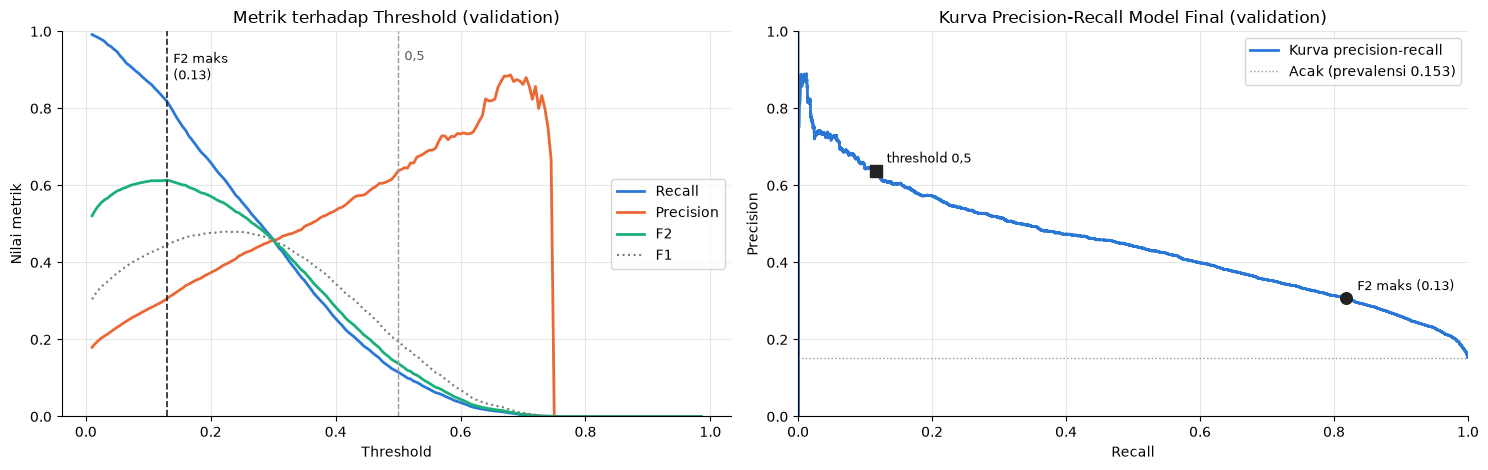

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
for kol, warna, nama in [("recall", WARNA_METRIK["recall"], "Recall"), ("precision", WARNA_METRIK["precision"], "Precision"),
                         ("f2", WARNA_METRIK["f2"], "F2"), ("f1", "#7a7a7a", "F1")]:
    ax.plot(kurva_final["threshold"], kurva_final[kol], lw=2 if kol != "f1" else 1.5,
            ls="-" if kol != "f1" else ":", color=warna, label=nama)
ax.axvline(THRESHOLD, color="#222222", lw=1.2, ls="--")
ax.axvline(0.5, color="#9A9A9A", lw=1, ls="--")
ax.text(THRESHOLD + 0.01, 0.95, f"F2 maks\n({THRESHOLD})", fontsize=9, va="top")
ax.text(0.51, 0.95, "0,5", fontsize=9, va="top", color="#555555")
ax.set_xlabel("Threshold")
ax.set_ylabel("Nilai metrik")
ax.set_ylim(0, 1)
ax.set_title("Metrik terhadap Threshold (validation)")
ax.legend(loc="center right")

ax = axes[1]
pr_p, pr_r, _ = precision_recall_curve(y_val, prob["final"])
ax.plot(pr_r, pr_p, color=WARNA_METRIK["recall"], lw=2, label="Kurva precision-recall")
ax.axhline(y_val.mean(), color="#9A9A9A", ls=":", lw=1, label=f"Acak (prevalensi {y_val.mean():.3f})")
for nama, t, mk in [("threshold 0,5", 0.5, "s"), (f"F2 maks ({THRESHOLD})", THRESHOLD, "o")]:
    m_ = ev.metrics_at_threshold(y_val, prob["final"], t)
    ax.scatter(m_["recall"], m_["precision"], s=70, marker=mk, color="#222222", zorder=3)
    ax.annotate(nama, (m_["recall"], m_["precision"]), xytext=(8, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Kurva Precision-Recall Model Final (validation)")
ax.legend(loc="upper right")
fig.tight_layout()
viz.save_fig(fig, "fu1_04_pemilihan_threshold")
plt.show()

**Interpretasi:** Tabel memperlihatkan pertukaran antara recall dan precision pada setiap kriteria:

| Kriteria | Threshold | Recall | Precision | Ditandai berisiko |
|---|---|---|---|---|
| Bawaan | 0,500 | 11,56% | 63,76% | 2,77% |
| F1 maksimum | 0,220 | 61,94% | 39,25% | 24,14% |
| **F2 maksimum** | **0,130** | **81,82%** | **30,65%** | **40,83%** |
| Youden's J | 0,135 | 80,54% | 31,20% | 39,49% |
| Recall minimal 80% | 0,135 | 80,54% | 31,20% | 39,49% |

Dengan threshold **0,13** (F2 maksimum), model menemukan 4.297 dari 5.252 responden diabetes. Jumlah yang terlewat turun dari 4.645 menjadi 955, dan F2 naik dari 0,1382 menjadi 0,6134. Harganya, *false positive* naik dari 345 menjadi 9.722, dan precision turun menjadi 30,65%. Artinya, dari setiap 10 orang yang ditandai berisiko, sekitar 3 orang benar-benar diabetes.

Titik kerja ini (recall 81,82%, specificity 66,57%) berada di wilayah yang mirip dengan alat skrining mandiri ADA (sensitivitas 79%, spesifisitas 67%). Perbandingan ini hanya sebagai gambaran, karena populasi dan definisi labelnya berbeda. Alat ADA mendeteksi diabetes yang belum terdiagnosis, sedangkan label di data ini berasal dari diagnosis yang dilaporkan responden.

Dari grafik kiri, kurva F2 cukup datar di sekitar puncaknya. Nilainya tetap di atas 0,60 pada threshold 0,075 sampai 0,16, jadi pilihan 0,13 tidak sensitif terhadap perubahan kecil. Kurva precision terlihat bergerigi di threshold tinggi karena di wilayah itu hanya segelintir responden yang diprediksi positif. Grafik kanan menunjukkan kedua titik kerja berada di kurva precision-recall yang sama. Yang berubah hanya posisi di kurva tersebut, bukan kualitas modelnya.

## **8. Uji Stabilitas Threshold**

Threshold di atas dipilih dan diukur di data yang sama, jadi hasilnya cenderung sedikit optimis. Untuk mengecek seberapa besar efek ini tanpa menyentuh data test, data validation dibagi dua secara stratified. Threshold dipilih di satu bagian, lalu diukur di bagian lainnya, dan proses ini dilakukan bergantian.

In [10]:
skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=config.SEED)
baris = []
for i, (idx_pilih, idx_uji) in enumerate(skf.split(prob["final"], y_val), start=1):
    t = ev.pick_threshold(ev.threshold_curve(y_val[idx_pilih], prob["final"][idx_pilih]), "f2")
    m_dalam = ev.metrics_at_threshold(y_val[idx_pilih], prob["final"][idx_pilih], t)
    m_luar = ev.metrics_at_threshold(y_val[idx_uji], prob["final"][idx_uji], t)
    baris.append({"lipatan": i, "threshold dipilih": t, "F2 di bagian pemilihan": m_dalam["f2"],
                  "F2 di bagian uji": m_luar["f2"], "recall bagian uji": m_luar["recall"],
                  "precision bagian uji": m_luar["precision"]})
stabilitas = pd.DataFrame(baris)
display(stabilitas.round(4))
print(f"Rata-rata penurunan F2 saat diukur di data yang tidak dipakai memilih: "
      f"{(stabilitas['F2 di bagian pemilihan'] - stabilitas['F2 di bagian uji']).mean():.4f}")

,lipatan,threshold dipilih,F2 di bagian pemilihan,F2 di bagian uji,recall bagian uji,precision bagian uji
0,1,0.125,0.6128,0.6126,0.8256,0.3015
1,2,0.105,0.6169,0.6077,0.8564,0.2811


Rata-rata penurunan F2 saat diukur di data yang tidak dipakai memilih: 0.0047


**Interpretasi:** Kedua bagian data validation memilih threshold yang sedikit berbeda, yaitu 0,125 dan 0,105, keduanya di sekitar threshold penuh (0,13). F2 di bagian uji (0,6126 dan 0,6077) hanya sedikit lebih rendah dari F2 di bagian pemilihan (0,6128 dan 0,6169), dengan rata-rata penurunan 0,0047. Recall di bagian uji berada di 82,56% sampai 85,64%.

Artinya ada sedikit optimisme ketika threshold dipilih dan diukur di data yang sama, tetapi besarnya kecil. Threshold yang berbeda tidak banyak mengubah F2 karena kurva F2 datar di wilayah ini. Di data test, F2 diperkirakan sedikit lebih rendah dari angka validation.

## **9. Ablation 2 x 2: Dampak Setiap Komponen Fitur Unik**

Empat skenario dibandingkan di data validation. Semuanya memakai seed 42 dan arsitektur yang sama:

| Skenario | Loss | Threshold |
|---|---|---|
| A. Tanpa fitur unik | BCE | 0,5 |
| B. Hanya threshold | BCE | F2 maksimum milik model BCE |
| C. Hanya Focal Loss | Focal terbaik | 0,5 |
| D. Fitur unik lengkap | Focal terbaik | F2 maksimum milik model Focal |

Threshold skenario B dan D dipilih dengan kriteria F2 yang sama, masing-masing dari probabilitas modelnya sendiri.

In [11]:
t_bce = ev.pick_threshold(ev.threshold_curve(y_val, prob["bce"]), "f2")
t_focal = ev.pick_threshold(ev.threshold_curve(y_val, prob["focal"]), "f2")
skenario = {
    "A. Tanpa fitur unik": (prob["bce"], 0.5),
    "B. Hanya threshold": (prob["bce"], t_bce),
    "C. Hanya Focal Loss": (prob["focal"], 0.5),
    "D. Fitur unik lengkap": (prob["focal"], t_focal),
}
ablation = pd.DataFrame({nama: {**ev.metrics_at_threshold(y_val, p, t), **ev.ranking_metrics(y_val, p)}
                         for nama, (p, t) in skenario.items()}).T
kolom_abl = ["threshold", "recall", "precision", "specificity", "f1", "f2", "accuracy",
             "persen_diprediksi_positif", "pr_auc", "roc_auc", "tp", "fp", "fn"]
ablation = ablation[kolom_abl].astype({"tp": int, "fp": int, "fn": int})
ablation.to_csv(config.RESULTS_DIR / "05_ablation_2x2_validation.csv")
display(ablation.round(4))

,threshold,recall,precision,specificity,f1,f2,accuracy,persen_diprediksi_positif,pr_auc,roc_auc,tp,fp,fn
A. Tanpa fitur unik,0.500,0.1156,0.6376,0.9881,0.1957,0.1382,0.8547,0.0277,0.4475,0.8184,607,345,4645
B. Hanya threshold,0.130,0.8182,0.3065,0.6657,0.4460,0.6134,0.6890,0.4083,0.4475,0.8184,4297,9722,955
C. Hanya Focal Loss,0.500,0.1687,0.5891,0.9787,0.2623,0.1968,0.8548,0.0438,0.4473,0.8181,886,618,4366
D. Fitur unik lengkap,0.335,0.8254,0.3020,0.6554,0.4422,0.6129,0.6814,0.4181,0.4473,0.8181,4335,10020,917


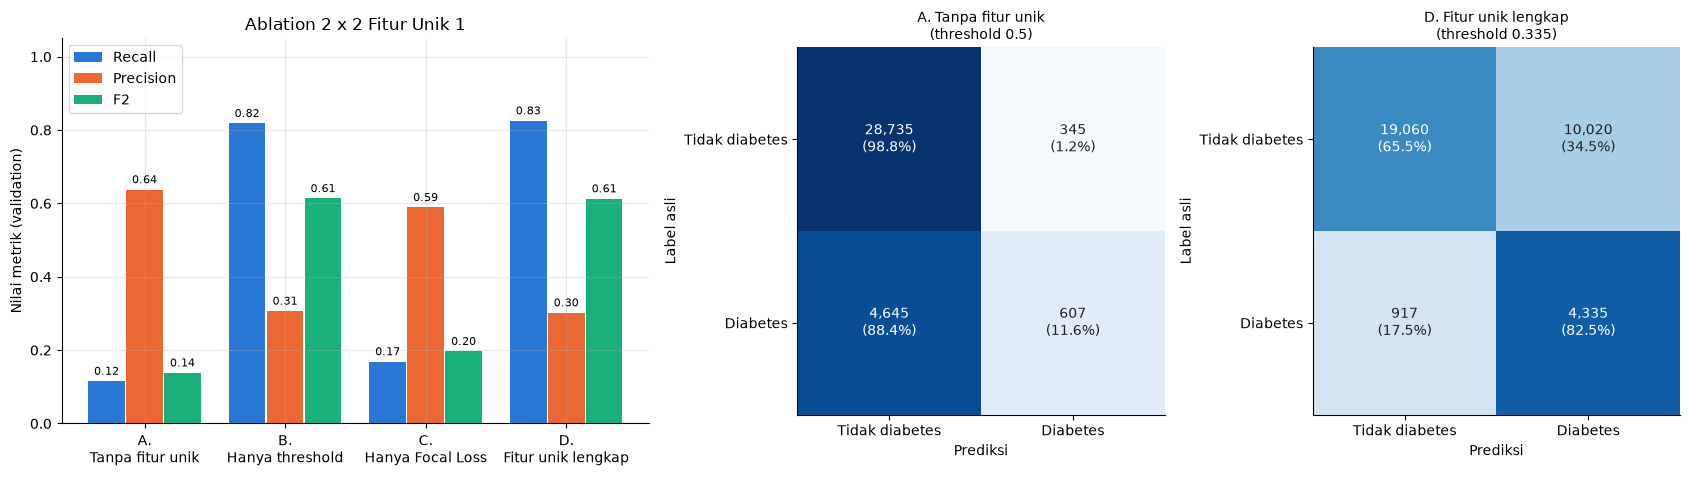

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.6, 1, 1]})
ax = axes[0]
x = np.arange(len(ablation))
lebar = 0.26
for i, (kol, nama) in enumerate([("recall", "Recall"), ("precision", "Precision"), ("f2", "F2")]):
    bar = ax.bar(x + (i - 1) * (lebar + 0.01), ablation[kol], width=lebar, color=WARNA_METRIK[kol], label=nama)
    for b, v in zip(bar, ablation[kol]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [s.replace(". ", ".\n") for s in ablation.index])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Nilai metrik (validation)")
ax.set_title("Ablation 2 x 2 Fitur Unik 1")
ax.legend(loc="upper left")

for ax, nama in zip(axes[1:], ["A. Tanpa fitur unik", "D. Fitur unik lengkap"]):
    p, t = skenario[nama]
    m_ = ev.metrics_at_threshold(y_val, p, t)
    cm = np.array([[m_["tn"], m_["fp"]], [m_["fn"], m_["tp"]]])
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})", ha="center", va="center", fontsize=10,
                    color="white" if cm_pct[i, j] > 0.6 else "#222222")
    lbl = [config.CLASS_LABELS[0], config.CLASS_LABELS[1]]
    ax.set_xticks([0, 1], lbl)
    ax.set_yticks([0, 1], lbl)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label asli")
    ax.grid(False)
    ax.set_title(f"{nama}\n(threshold {t})", fontsize=10)
fig.tight_layout()
viz.save_fig(fig, "fu1_05_ablation_2x2")
plt.show()

**Interpretasi:** Ablation 2 x 2 memisahkan dampak kedua komponen dengan jelas:

| Skenario | Recall | Precision | F2 |
|---|---|---|---|
| A. Tanpa fitur unik | 11,56% | 63,76% | 0,1382 |
| B. Hanya threshold | 81,82% | 30,65% | 0,6134 |
| C. Hanya Focal Loss | 16,87% | 58,91% | 0,1968 |
| D. Focal + threshold | 82,54% | 30,20% | 0,6129 |

1. **Threshold adalah komponen yang memberi dampak.** Dari A ke B, recall naik dari 11,56% menjadi 81,82% dan F2 naik lebih dari empat kali lipat, tanpa mengubah model sama sekali.
2. **Focal Loss hanya sedikit membantu kalau threshold tetap 0,5** (C sedikit lebih baik dari A). Ini terjadi karena probabilitasnya bergeser ke atas, sehingga efeknya mirip menurunkan threshold. Threshold optimal untuk model Focal adalah 0,335, bukan 0,5, yang membuktikan pergeseran itu.
3. **Setelah masing-masing model memakai threshold optimalnya, Focal Loss tidak menambah apa pun.** D (F2 0,6129) tidak lebih baik dari B (F2 0,6134), dan PR-AUC keduanya hampir sama (0,4473 berbanding 0,4475).

Karena itu, model final memakai skenario **B**, yaitu BCE dengan threshold F2. Skenario ini memberi hasil terbaik, probabilitasnya tetap dekat dengan peluang sebenarnya untuk aplikasi, dan paling sederhana. Focal Loss tetap tercatat sebagai bagian dari fitur unik yang diuji dan ditolak berdasarkan bukti.

## **10. Menyimpan Model Final dan Konfigurasi Inferensi**

File `models/model_config.json` berisi semua informasi yang dibutuhkan aplikasi untuk melakukan prediksi yang sama persis dengan notebook ini, yaitu lokasi model, urutan fitur, threshold, dan loss yang dipakai. Aplikasi cukup membaca file ini, `scaler.joblib`, dan `mlp_final.keras`.

In [13]:
m_val = ev.metrics_at_threshold(y_val, prob["final"], THRESHOLD)
model_config = {
    "model_path": "models/mlp_final.keras",
    "scaler_path": "models/scaler.joblib",
    "feature_cols": config.FEATURE_COLS,
    "class_labels": {str(k): v for k, v in config.CLASS_LABELS.items()},
    "konfigurasi": cfg_final,
    "loss": label_loss[pilih_e6],
    "seed": 42,
    "threshold": THRESHOLD,
    "kriteria_threshold": "F2 maksimum di data validation",
    "metrik_validation_pada_threshold": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_val.items()},
    "metrik_validation_ranking": {k: round(v, 4) for k, v in ev.ranking_metrics(y_val, prob["final"]).items()},
    "test_fingerprint": data["test_fingerprint"],
    "catatan": "Semua metrik di file ini berasal dari data validation. Hasil data test ada di notebook 07.",
}
M.save_json(model_config, MODEL_CONFIG_PATH)
print(json.dumps(model_config, indent=2, ensure_ascii=False)[:2500])

{
  "model_path": "models/mlp_final.keras",
  "scaler_path": "models/scaler.joblib",
  "feature_cols": [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income"
  ],
  "class_labels": {
    "0": "Tidak diabetes",
    "1": "Diabetes"
  },
  "konfigurasi": {
    "hidden_units": [
      128,
      64,
      32,
      16
    ],
    "dropout": 0.0,
    "l2": 1e-06,
    "batch_norm": true,
    "learning_rate": 0.0043925333029596605,
    "batch_size": 256
  },
  "loss": "BCE",
  "seed": 42,
  "threshold": 0.13,
  "kriteria_threshold": "F2 maksimum di data validation",
  "metrik_validation_pada_threshold": {
    "threshold": 0.13,
    "precision": 0.3065,
    "recall": 0.8182,
    "specificity": 0.6657,
    "f1"

In [14]:
# Uji alur inferensi seperti di aplikasi: model dan scaler dari file, input berupa dictionary
cfg_app = json.load(open(MODEL_CONFIG_PATH, encoding="utf-8"))
model_app = keras.models.load_model(ROOT / cfg_app["model_path"], compile=False)
scaler_app = prep.load_scaler()

contoh = data["X_val_raw"].iloc[[0, 1, 2]]
for i, (_, baris_raw) in enumerate(contoh.iterrows()):
    input_form = {col: int(baris_raw[col]) for col in cfg_app["feature_cols"]}
    p_app = float(model_app.predict(prep.transform_features(pd.DataFrame([input_form]), scaler_app), verbose=0)[0, 0])
    status = "BERISIKO" if p_app >= cfg_app["threshold"] else "risiko rendah"
    print(f"Responden {i + 1}: probabilitas {p_app:.4f} (notebook: {prob['final'][i]:.4f}) -> {status} "
          f"| label asli: {config.CLASS_LABELS[int(y_val[i])]}")

Responden 1: probabilitas 0.0100 (notebook: 0.0100) -> risiko rendah | label asli: Tidak diabetes
Responden 2: probabilitas 0.0516 (notebook: 0.0516) -> risiko rendah | label asli: Tidak diabetes
Responden 3: probabilitas 0.0547 (notebook: 0.0547) -> risiko rendah | label asli: Tidak diabetes


**Interpretasi:** Konfigurasi inferensi tersimpan di `models/model_config.json`, berisi lokasi model dan scaler, urutan 21 fitur, threshold 0,13, dan metrik validation pada threshold tersebut. Uji alur aplikasi pada tiga responden menghasilkan probabilitas yang sama persis dengan notebook (0,0100, 0,0516, dan 0,0547). Ketiganya berada di bawah threshold sehingga dikategorikan risiko rendah, dan sesuai dengan label aslinya (tidak diabetes).

## **11. Kesimpulan**

Fitur unik pertama, yaitu penanganan ketidakseimbangan kelas, diterapkan sebagai berikut:

| Komponen | Hasil di data validation | Keputusan |
|---|---|---|
| Focal Loss (4 variasi) dan BCE berbobot | PR-AUC setara atau lebih rendah dari BCE. Probabilitas bergeser dari peluang sebenarnya | Diuji, **tidak dipakai** |
| Threshold F2 (0,13) | Recall 11,56% menjadi 81,82%, F2 0,1382 menjadi 0,6134. Penurunan F2 di uji dua bagian hanya 0,0047 | **Dipakai** |

Model final yang dibekukan untuk Tugas 1 dan UTS:
- `models/mlp_final.keras`: MLP [128-64-32-16], ReLU, tanpa dropout, BatchNorm, L2 1e-6, Adam 0,0044, batch 256, loss BCE, seed 42 (konfigurasi hasil uji konfirmasi Random Search di notebook 04b)
- `models/model_config.json`: threshold **0,13** (F2 maksimum di data validation)
- `models/scaler.joblib`: scaler dari notebook 02

Harga dari recall yang tinggi adalah precision 30,65% dan 40,83% responden ditandai berisiko. Untuk alat skrining awal, pertukaran ini masih bisa diterima karena tindak lanjutnya hanya anjuran pemeriksaan gula darah. Hal ini perlu dijelaskan di laporan dan di aplikasi.

Semua angka di notebook ini berasal dari data validation. **Performa akhir, termasuk perbandingan skenario A dan B, diukur sekali di data test pada notebook 07.**

**Langkah berikutnya:** notebook 06 (fitur unik 2) menerapkan Integrated Gradients pada `mlp_final.keras` untuk menjelaskan faktor yang paling memengaruhi setiap prediksi.

### **Referensi**

- Lin, T.-Y., Goyal, P., Girshick, R., He, K., & Dollár, P. (2017). Focal Loss for Dense Object Detection. *Proceedings of the IEEE International Conference on Computer Vision (ICCV)*. https://arxiv.org/abs/1708.02002
- Bang, H., dkk. (2009). Development and Validation of a Patient Self-assessment Score for Diabetes Risk. *Annals of Internal Medicine*, 151(11), 775-783. https://pmc.ncbi.nlm.nih.gov/articles/PMC2797952
- Saito, T., & Rehmsmeier, M. (2015). The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets. *PLOS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432